### Name - Yash Bhardwaj
### Batch - A - A1
### Roll No - 09

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [4]:
df = pd.read_csv("Wholesale customers data.csv")

In [5]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [6]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [8]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [10]:
features = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper', 'Delicassen'
]
X = data[features].copy()

# Handle missing values if present
X = X.fillna(X.median())

In [12]:
print("\nStatistical Summary:")
X.describe()


Statistical Summary:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


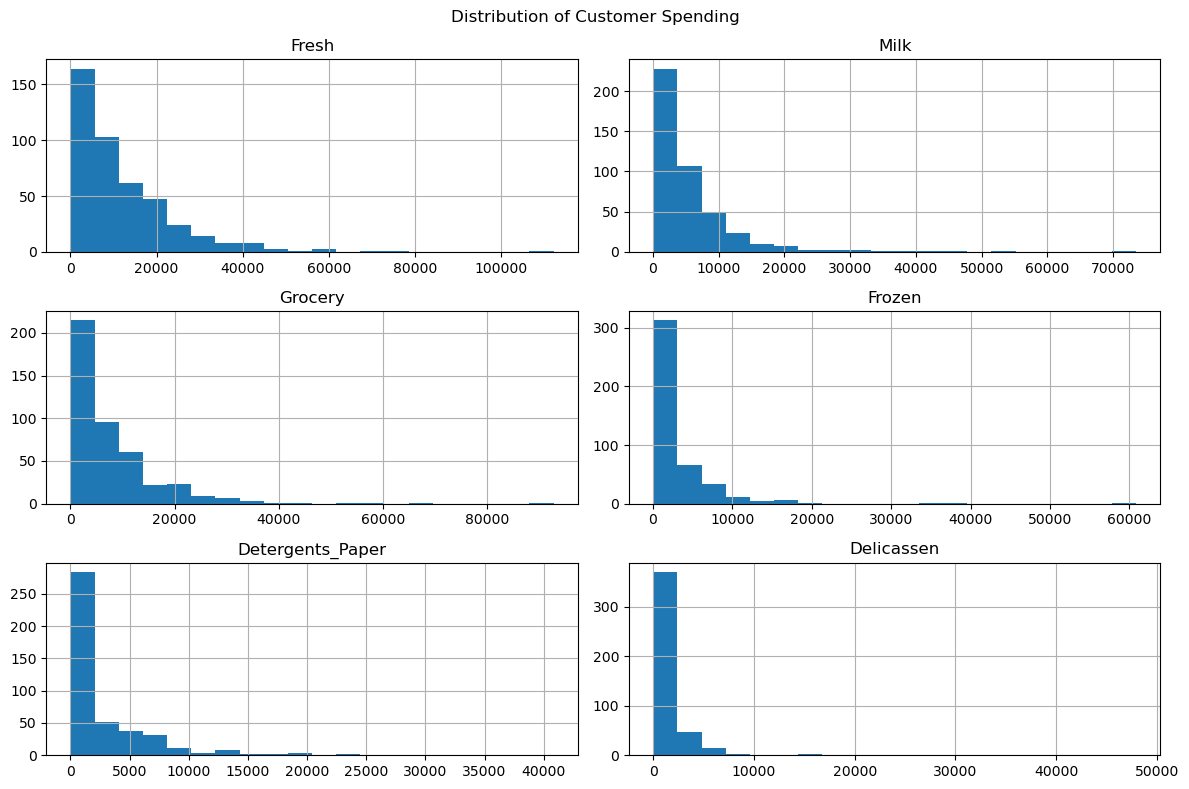

In [13]:
X.hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribution of Customer Spending")
plt.tight_layout()
plt.show()


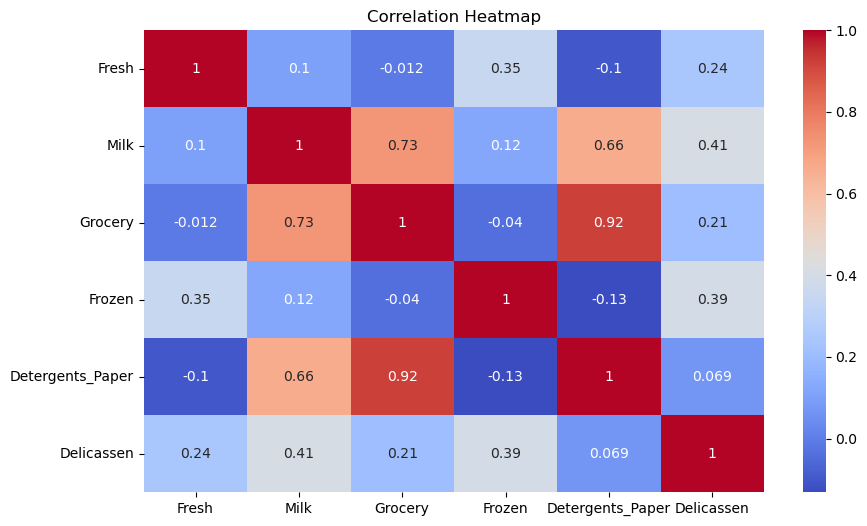

In [14]:
plt.figure(figsize=(10, 6))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

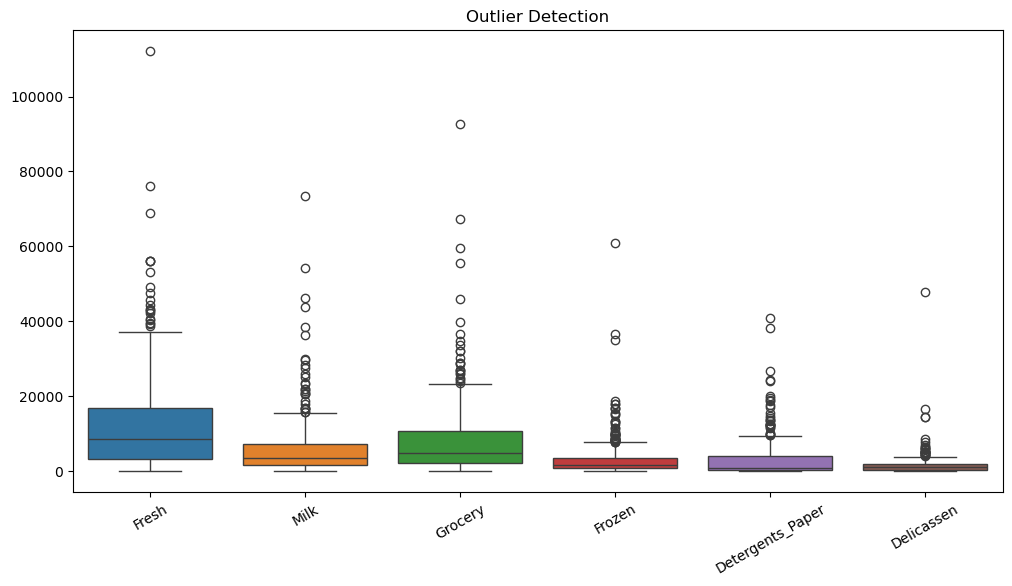

In [15]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.xticks(rotation=30)
plt.title("Outlier Detection")
plt.show()

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

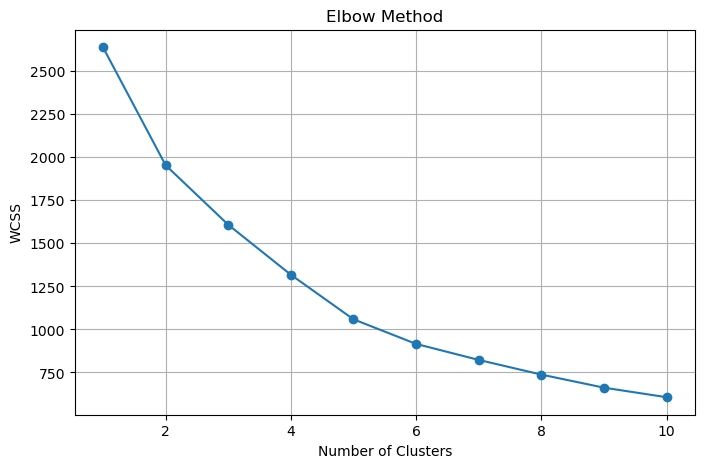

In [17]:
wcss = []

for i in range(1, 11):
    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=20
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()

In [18]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_scaled)

data['KMeans_Cluster'] = kmeans_labels

print("\nK-Means Cluster Counts:")
print(data['KMeans_Cluster'].value_counts().sort_index())


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(



K-Means Cluster Counts:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64


In [19]:
hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

data['Hierarchical_Cluster'] = hierarchical_labels

print("\nHierarchical Cluster Counts:")
print(data['Hierarchical_Cluster'].value_counts().sort_index())



Hierarchical Cluster Counts:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64


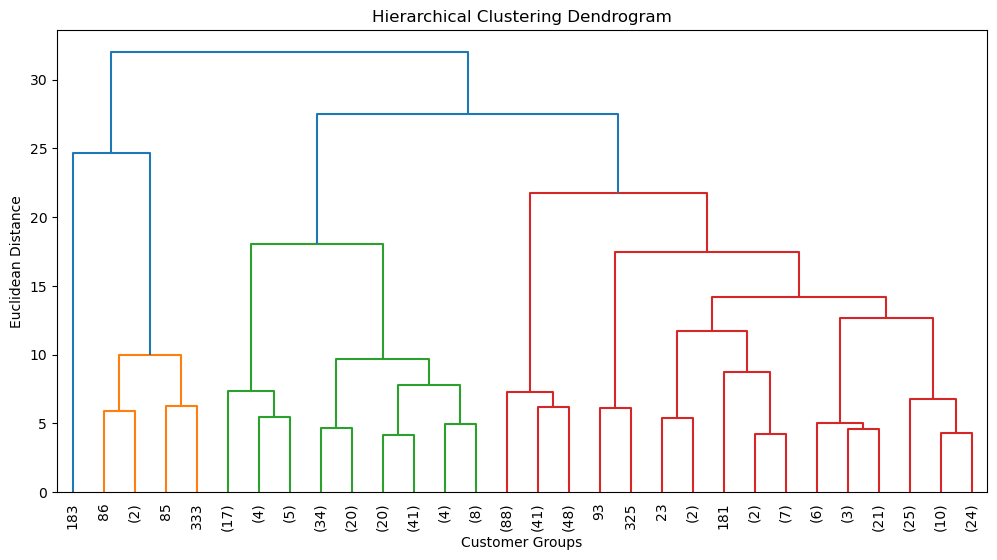

In [20]:
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.show()


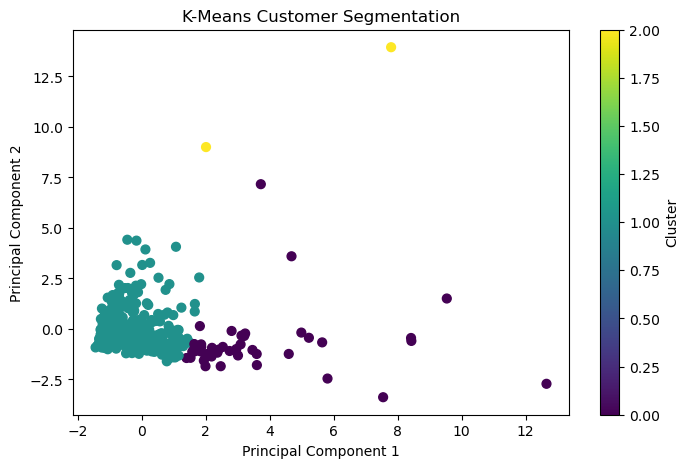

In [21]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# K-Means Visualization
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=40
)

plt.title("K-Means Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

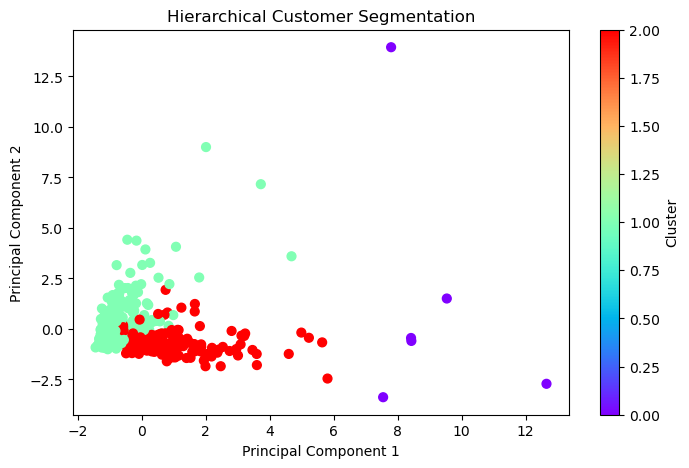

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap='rainbow',
    s=40
)

plt.title("Hierarchical Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [23]:
print("\nMODEL PERFORMANCE COMPARISON")

print("\nK-Means:")
print("Silhouette Score:",
      silhouette_score(X_scaled, kmeans_labels))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, kmeans_labels))

print("\nHierarchical Clustering:")
print("Silhouette Score:",
      silhouette_score(X_scaled, hierarchical_labels))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_scaled, hierarchical_labels))


MODEL PERFORMANCE COMPARISON

K-Means:
Silhouette Score: 0.5482872649700601
Davies-Bouldin Index: 0.9279350629308419

Hierarchical Clustering:
Silhouette Score: 0.2646091480214908
Davies-Bouldin Index: 1.2845213578374575


In [24]:
print("\nK-Means Cluster Profiles:")
print(data.groupby('KMeans_Cluster')[features].mean().round(2))

print("\nHierarchical Cluster Profiles:")
print(data.groupby('Hierarchical_Cluster')[features].mean().round(2))



K-Means Cluster Profiles:
                   Fresh      Milk   Grocery    Frozen  Detergents_Paper  \
KMeans_Cluster                                                             
0               10440.93  19386.42  28656.09   2190.24          13327.80   
1               12062.91   4115.10   5534.97   2940.68           1696.17   
2               34782.00  30367.00  16898.00  48701.50            755.50   

                Delicassen  
KMeans_Cluster              
0                  2374.20  
1                  1299.11  
2                 26776.00  

Hierarchical Cluster Profiles:
                         Fresh      Milk   Grocery   Frozen  Detergents_Paper  \
Hierarchical_Cluster                                                            
0                     27477.00  43542.17  54588.50  8285.67          25018.33   
1                     15048.93   3017.30   3791.76  3837.32            758.01   
2                      5794.24   9419.89  13761.74  1461.76           5913.38   

         

In [25]:
df.to_csv("Customer_Segmentation_Results.csv", index=False)

print("\nClustering completed successfully!")


Clustering completed successfully!
